In [4]:
import pandas as pd
from sklearn.datasets import load_iris


iris = load_iris()


df = pd.DataFrame(
    iris.data,
    columns=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
)


df["species"] = [
    iris.target_names[i] for i in iris.target
]       
df.to_csv("iris.csv", index=False)

print("CSV file successfully save ho gayi!")
print(df.head())
print("Dataset shape:", df.shape)

CSV file successfully save ho gayi!
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Dataset shape: (150, 5)


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("iris.csv")

print("First 5 rows:")
print(df.head())
print("Dataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print(df.columns)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["species"].value_counts())

First 5 rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Dataset shape: (150, 5)
Total rows: 150
Total columns: 5
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2

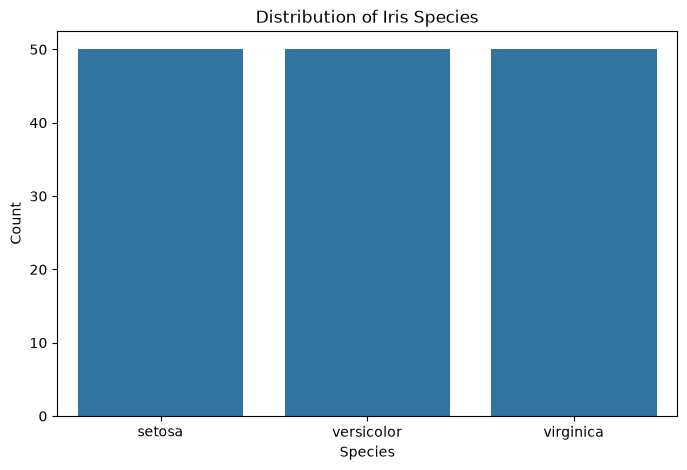

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

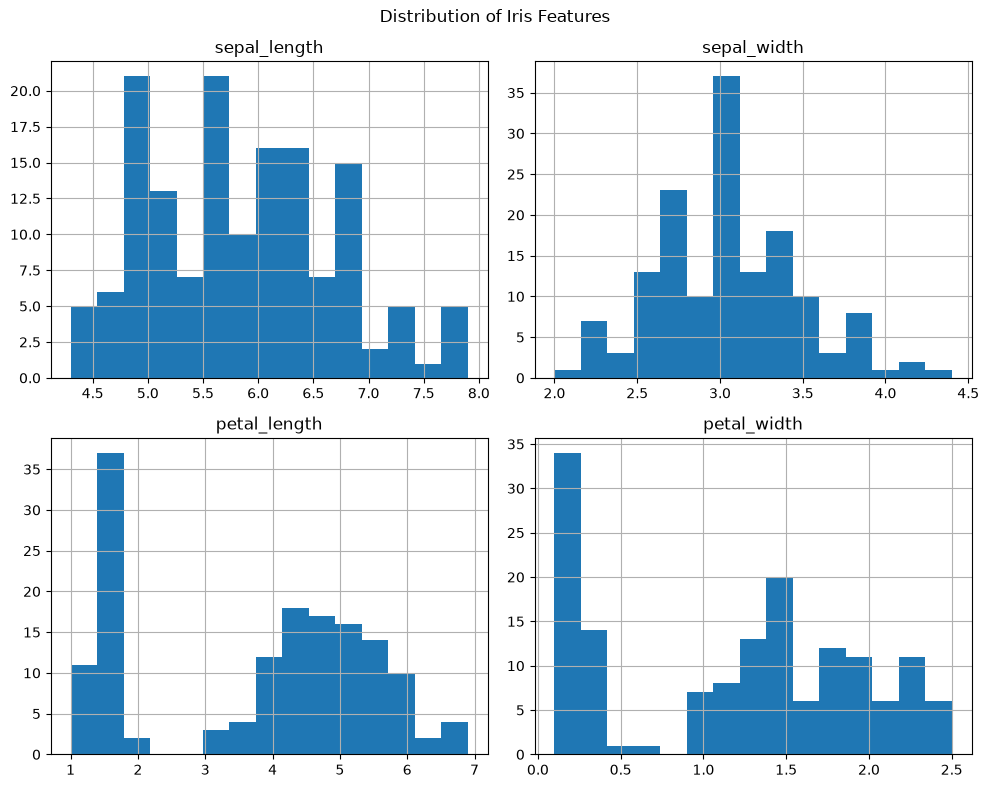

In [12]:
df[["sepal_length", "sepal_width",
    "petal_length", "petal_width"]].hist(
    figsize=(10, 8),
    bins=15
)

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

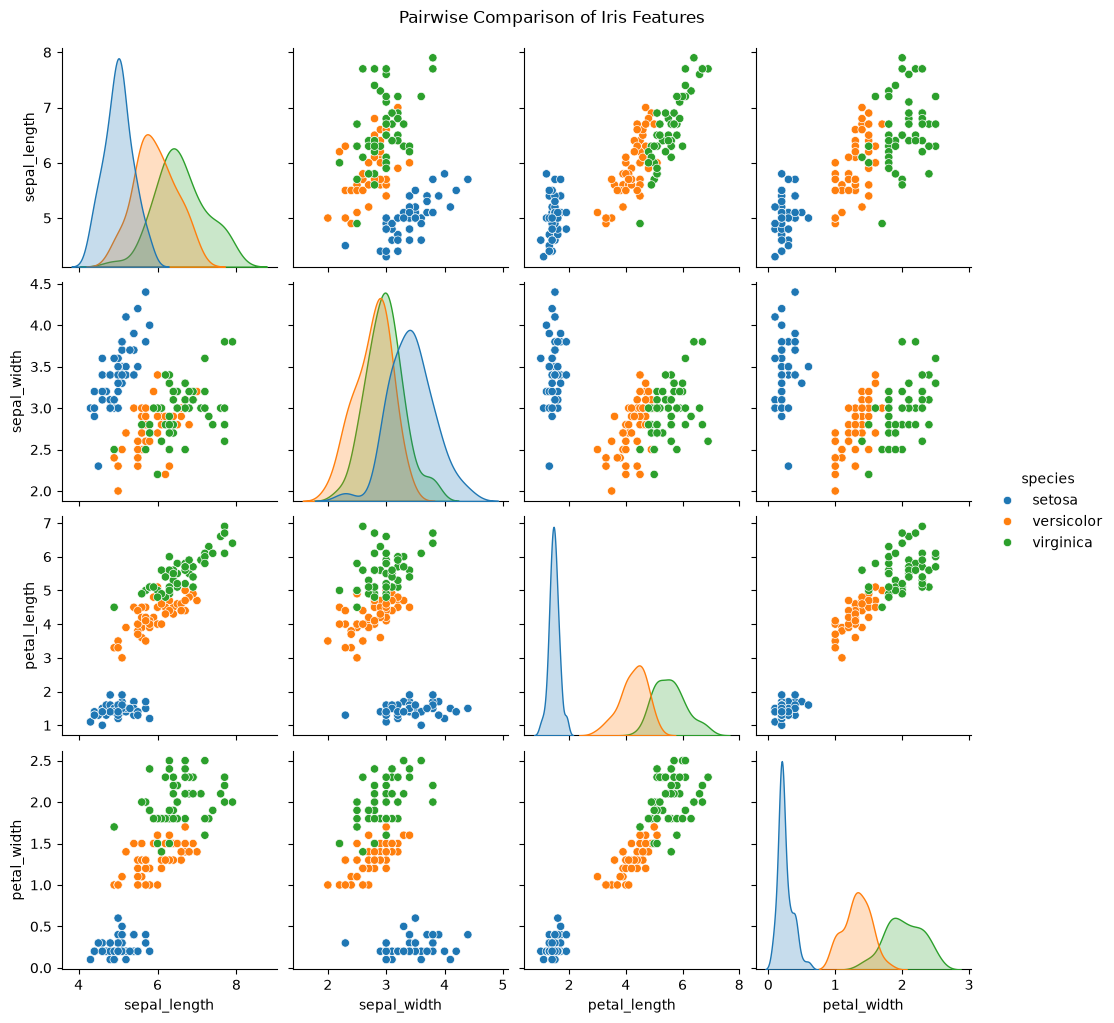

In [13]:
sns.pairplot(df, hue="species")
plt.suptitle("Pairwise Comparison of Iris Features", y=1.02)
plt.show()

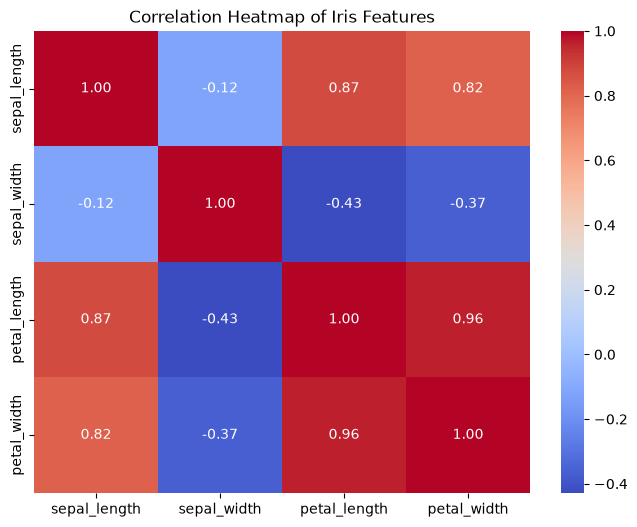

In [14]:
plt.figure(figsize=(8, 6))

correlation = df[
    ["sepal_length", "sepal_width",
     "petal_length", "petal_width"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Iris Features")
plt.show()

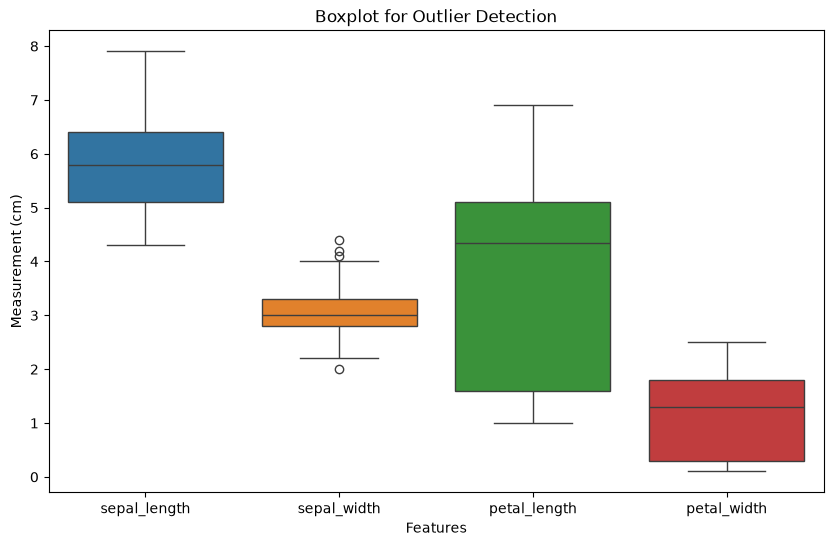

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[
        ["sepal_length", "sepal_width",
         "petal_length", "petal_width"]
    ]
)

plt.title("Boxplot for Outlier Detection")
plt.xlabel("Features")
plt.ylabel("Measurement (cm)")
plt.show()

In [16]:
print("Missing values:")
print(df.isnull().sum())


Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [17]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


In [18]:
df = df.drop_duplicates()

print("Dataset shape after cleaning:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Dataset shape after cleaning: (149, 5)
Duplicate rows remaining: 0


In [19]:
df.to_csv("iris_cleaned.csv", index=False)
print("Cleaned dataset successfully saved!")

Cleaned dataset successfully saved!


In [21]:
X = df[
    ["sepal_length", "sepal_width",
     "petal_length", "petal_width"]
]

y = df["species"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (149, 4)
y shape: (149,)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (119, 4)
Testing features: (30, 4)
Training target: (119,)
Testing target: (30,)


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X.head())

print(X_scaled[:5])

   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
[[-0.8980334   1.01240113 -1.33325507 -1.30862368]
 [-1.13956224 -0.1373532  -1.33325507 -1.30862368]
 [-1.38109108  0.32254853 -1.39001364 -1.30862368]
 [-1.5018555   0.09259766 -1.2764965  -1.30862368]
 [-1.01879782  1.242352   -1.33325507 -1.30862368]]


In [24]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=200)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Actual species:")
print(y_test.values)

print("\nPredicted species:")
print(y_pred_lr)

Actual species:
<ArrowStringArray>
['versicolor', 'versicolor',  'virginica',     'setosa',  'virginica',
 'versicolor', 'versicolor',     'setosa',  'virginica',  'virginica',
     'setosa',     'setosa',     'setosa', 'versicolor',  'virginica',
     'setosa', 'versicolor',     'setosa',  'virginica',     'setosa',
 'versicolor',  'virginica',     'setosa',     'setosa', 'versicolor',
 'versicolor',  'virginica',  'virginica',  'virginica', 'versicolor']
Length: 30, dtype: str

Predicted species:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica' 'setosa' 'setosa' 'setosa'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'setosa' 'versicolor' 'virginica' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'virginica' 'virginica' 'versicolor']


In [25]:
from sklearn.tree import DecisionTreeClassifier

# Create model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

# Train model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

print("Actual species:")
print(y_test.values)

print("\nDecision Tree Predictions:")
print(y_pred_dt)

Actual species:
<ArrowStringArray>
['versicolor', 'versicolor',  'virginica',     'setosa',  'virginica',
 'versicolor', 'versicolor',     'setosa',  'virginica',  'virginica',
     'setosa',     'setosa',     'setosa', 'versicolor',  'virginica',
     'setosa', 'versicolor',     'setosa',  'virginica',     'setosa',
 'versicolor',  'virginica',     'setosa',     'setosa', 'versicolor',
 'versicolor',  'virginica',  'virginica',  'virginica', 'versicolor']
Length: 30, dtype: str

Decision Tree Predictions:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica' 'setosa' 'setosa' 'setosa'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'setosa' 'versicolor' 'versicolor' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'virginica' 'virginica' 'versicolor']


In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Logistic Regression evaluation
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, average="weighted")
lr_recall = recall_score(y_test, y_pred_lr, average="weighted")
lr_f1 = f1_score(y_test, y_pred_lr, average="weighted")

# Decision Tree evaluation
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, average="weighted")
dt_recall = recall_score(y_test, y_pred_dt, average="weighted")
dt_f1 = f1_score(y_test, y_pred_dt, average="weighted")

# Comparison table
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [lr_accuracy, dt_accuracy],
    "Precision": [lr_precision, dt_precision],
    "Recall": [lr_recall, dt_recall],
    "F1-Score": [lr_f1, dt_f1]
})

print(results.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.967      0.970   0.967     0.967
1        Decision Tree     0.933      0.933   0.933     0.933


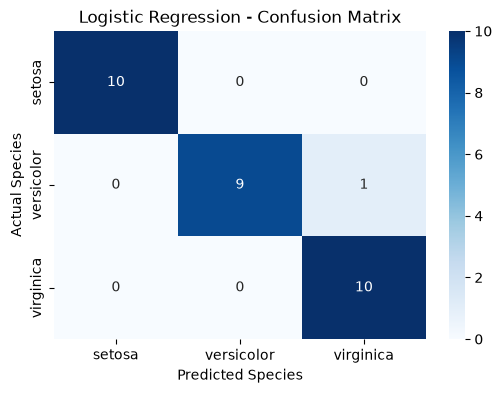

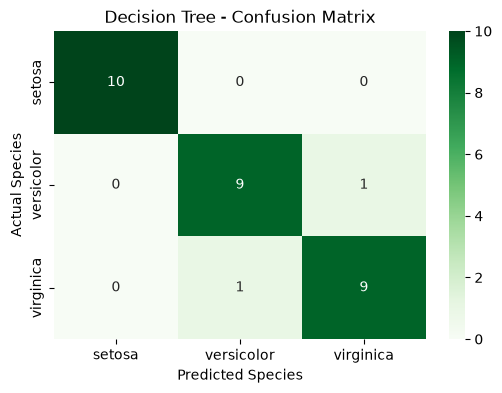

In [29]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Logistic Regression confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=200))
])

lr_scaled.fit(X_train, y_train)

y_pred_lr_scaled = lr_scaled.predict(X_test)

print("Scaled Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr_scaled))


Scaled Logistic Regression Accuracy: 0.9333333333333333


In [31]:
dt_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(
        random_state=42,
        max_depth=4
    ))
])

dt_scaled.fit(X_train, y_train)

y_pred_dt_scaled = dt_scaled.predict(X_test)

print("Scaled Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt_scaled))

Scaled Decision Tree Accuracy: 0.9333333333333333


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": y_pred_lr_scaled,
    "Decision Tree": y_pred_dt_scaled
}

comparison = []

for name, predictions in models.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="weighted"
        )
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.933      0.933   0.933     0.933
1        Decision Tree     0.933      0.933   0.933     0.933


In [33]:
import joblib

joblib.dump(lr_scaled, "logistic_regression_model.pkl")
joblib.dump(dt_scaled, "decision_tree_model.pkl")

print("Dono trained models successfully save ho gaye!")

Dono trained models successfully save ho gaye!


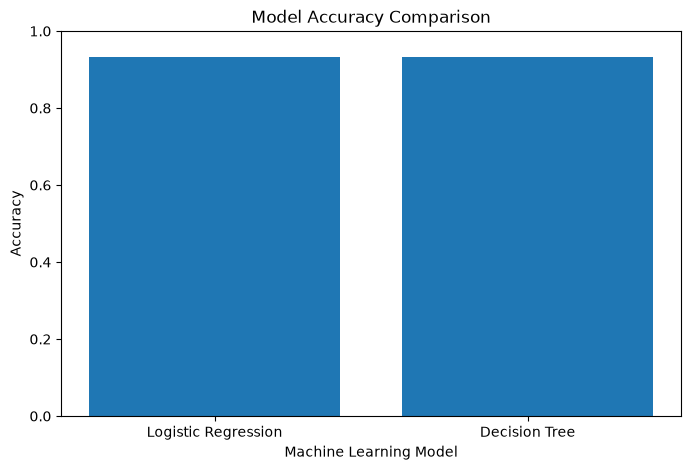

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

# Datheon — Multi-Class Benchmark Classification Pipeline

## Project Overview

This project implements a multi-class classification pipeline using the Iris dataset. It explores the dataset, performs data cleaning and feature scaling, trains two machine learning models, and compares their performance using standard evaluation metrics.

## Objectives

- Load and inspect the Iris dataset.
- Perform Exploratory Data Analysis (EDA).
- Handle duplicate records.
- Apply feature scaling using StandardScaler.
- Split the dataset into training and testing sets.
- Train and evaluate two classification algorithms.
- Compare model performance using evaluation metrics.
- Save trained models for future use.

## Dataset Information

The Iris dataset contains measurements of three flower species:

- Setosa
- Versicolor
- Virginica

**Features:**
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

**Target:** Species

| Property | Details |
|---|---|
| Original records | 150 |
| Features | 4 numerical columns |
| Target column | Species |
| Classes | 3 |
| Records after duplicate removal | 149 |

## Technologies and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib
- Jupyter Notebook

## Project Workflow

### 1. Data Loading and Inspection
Loaded the Iris dataset and examined its shape, column names, data types, summary statistics, missing values, and duplicate records.

### 2. Exploratory Data Analysis
Created visualizations to understand the dataset:
- Species distribution count plot
- Feature distribution histograms
- Pairplot for feature relationships
- Correlation heatmap
- Boxplots for potential outlier detection

### 3. Data Cleaning
Checked for missing values and removed one exact duplicate row.

### 4. Feature Scaling
Used StandardScaler within Scikit-learn pipelines to standardize features without leaking information from the test set into training.

### 5. Train-Test Split
Split the cleaned dataset into 80% training data and 20% testing data, using stratification to preserve class proportions.

### 6. Model Training
Trained two classification models:

- Logistic Regression
- Decision Tree Classifier

### 7. Model Evaluation
Evaluated the models using:
- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

### 8. Model Comparison
Compared the performance of both models using a metrics table and an accuracy bar chart.

## Model Evaluation Results

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.933 | 0.933 | 0.933 | 0.933 |
| Decision Tree | 0.933 | 0.933 | 0.933 | 0.933 |

Both models achieved **93.3% accuracy** on the current test split. Their evaluation scores were equal in this experiment.

## Saved Models

The trained model pipelines are saved as:

- `logistic_regression_model.pkl`
- `decision_tree_model.pkl`

These files contain the trained pipelines, including preprocessing where applicable.

## How to Run the Project

1. Clone or download this repository.
2. Open the project folder in Jupyter Notebook.
3. Install the required libraries:

   ```bash
   pip install pandas numpy matplotlib seaborn scikit-learn joblib jupyter
   ```

4. Open and run the project notebook from the first cell to the last.
5. Ensure the Iris dataset file is available if the notebook loads it from a CSV file.

## Conclusion

This project demonstrates a complete introductory multi-class classification workflow, from dataset inspection and exploratory analysis to preprocessing, model training, evaluation, comparison, and model saving.

Both Logistic Regression and Decision Tree achieved 93.3% accuracy on the current test set. Further testing with different splits or cross-validation could help assess how consistently the models perform.

## Author

**Muskan Chhawri**

## Project Name

**Datheon — Multi-Class Benchmark Classification Pipeline (Iris Dataset)**